# Áp dụng EHO ở nhiều bài toán

Notebook thử EHO trên các bài Rastrigin có số chiều khác nhau và một bài toán giả lập hai máy bơm. Ta sẽ xem một cấu hình tìm điểm tốt trên Rastrigin có cho kết quả tương tự khi dùng để chia lưu lượng bơm hay không. Các bảng và hình lưu sẵn dùng 25 seed của chế độ FULL.

In [1]:
from experiment_helpers.artifacts import save_experiment_artifacts

import os
from dataclasses import replace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from eho import EHOConfig
from objectives import rastrigin
from experiment_helpers.runner import (
    assert_reproducible, compare_configurations, results_frame, seeds_for,
)
from experiment_helpers.statistics import summarize_experiment_results

MODE = os.getenv("EHO_EXPERIMENT_MODE", "QUICK").upper()
seeds = seeds_for(MODE)
base = EHOConfig(population_size=20, max_generations=50)
print(MODE, seeds)
print(base)
assert_reproducible(rastrigin, base, seeds[0])
print("Kiểm tra tái lập cùng seed đã đạt.")

FULL [101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125]
EHOConfig(population_size=20, dimension=4, alpha=0.5, beta=0.1, max_generations=50, lower_bounds=(-5.12, -5.12, -5.12, -5.12), upper_bounds=(5.12, 5.12, 5.12, 5.12), random_seed=42)
Kiểm tra tái lập cùng seed đã đạt.


In [2]:
from dataclasses import asdict
from objectives.data_loader import load_pump_scenarios
from experiment_helpers.runner import maximum_overshoot, pump_grid_reference, run_multiple_seeds
from experiment_helpers.plotting import plot_convergence, plot_rastrigin_contour

def report(section, groups, contour_result=None):
    frame = results_frame(groups)
    summary = summarize_experiment_results(frame)
    display(summary)
    plot_convergence(groups)
    if contour_result is not None:
        plot_rastrigin_contour(contour_result)
    save_experiment_artifacts("experiment-4", section, MODE, seeds, frame, summary)
    plt.show()
    return summary

## 1. Rastrigin hai chiều

So sánh hai nhóm có số cá thể khác nhau nhưng chạy cùng số thế hệ. Trên bản đồ đường đồng mức, mỗi đường nối những điểm có cùng fitness. Dấu sao chỉ điểm tốt nhất của lần chạy minh họa. Bảng phía trên tổng hợp mọi seed, còn bản đồ chỉ vẽ seed đầu tiên để dễ nhìn.

,runs,minimum,mean,median,maximum,std,variance,seconds,evaluations,feasible_rate,violations
group,,,,,,,,,,,
P=5,25,2.174824e-05,0.014417,6.744820e-03,0.154104,0.030784,9.476722e-04,0.005023,255.0,1.0,8.20
P=20,25,2.892075e-09,0.000002,2.748412e-07,0.000026,0.000005,3.006571e-11,0.015865,1020.0,1.0,9.12


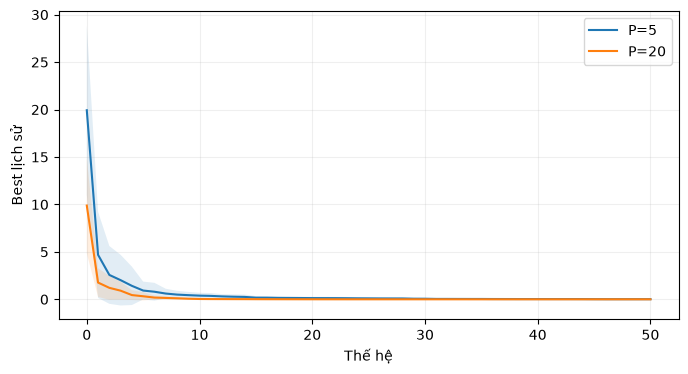

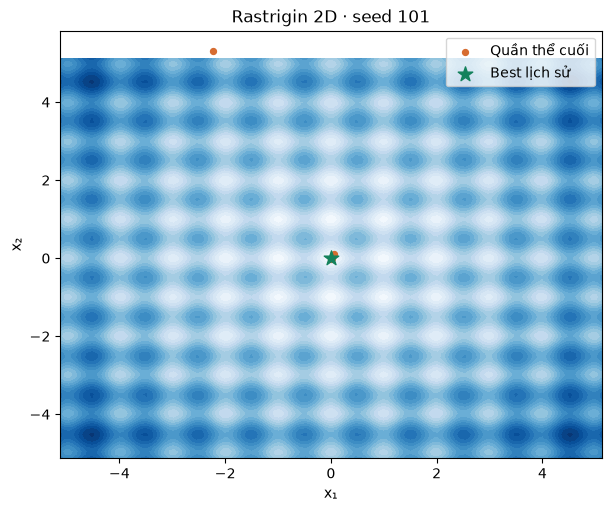

,runs,minimum,mean,median,maximum,std,variance,seconds,evaluations,feasible_rate,violations
group,,,,,,,,,,,
P=5,25,2.174824e-05,0.014417,6.744820e-03,0.154104,0.030784,9.476722e-04,0.005023,255.0,1.0,8.20
P=20,25,2.892075e-09,0.000002,2.748412e-07,0.000026,0.000005,3.006571e-11,0.015865,1020.0,1.0,9.12


In [3]:
two_d = {f"P={size}": EHOConfig(dimension=2, population_size=size) for size in (5, 20)}
two_results = compare_configurations(rastrigin, two_d, seeds)
report("rastrigin-2d", two_results, two_results["P=5"][0])

## 2. Rastrigin bốn chiều

Phần này thử các thiết lập gần ví dụ trong sách, tăng số cá thể hoặc số thế hệ, rồi thử thay alpha và beta. Chương trình lấy cấu hình có điểm trung bình cuối thấp nhất trong các cấu hình vừa thử để đem sang bài toán máy bơm.

,runs,minimum,mean,median,maximum,std,variance,seconds,evaluations,feasible_rate,violations
group,,,,,,,,,,,
Gần ví dụ sách,25,0.009001,0.115185,0.080530,0.418298,0.103422,1.069607e-02,0.005067,255.0,1.0,17.28
P=20,25,0.000017,0.000513,0.000359,0.002255,0.000526,2.769456e-07,0.015121,1020.0,1.0,17.52
G=100,25,0.001563,0.064719,0.039160,0.304159,0.073518,5.404826e-03,0.010127,505.0,1.0,34.84
Alpha 0.7,25,0.003548,0.070732,0.029655,0.532394,0.114556,1.312316e-02,0.005102,255.0,1.0,16.24
Beta 0.3,25,0.118259,2.412272,1.188444,15.697699,3.445535,1.187171e+01,0.005232,255.0,1.0,16.36


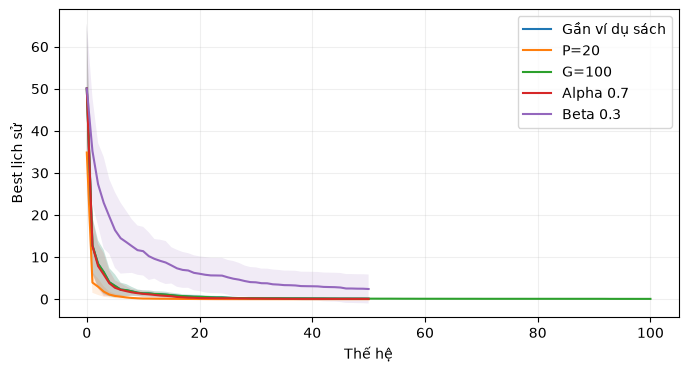

Cấu hình được chọn theo mean 4D: P=20


In [4]:
book_config = EHOConfig()
four_d = {
    "Gần ví dụ sách": book_config,
    "P=20": replace(book_config, population_size=20),
    "G=100": replace(book_config, max_generations=100),
    "Alpha 0.7": replace(book_config, alpha=0.7),
    "Beta 0.3": replace(book_config, beta=0.3),
}
four_results = compare_configurations(rastrigin, four_d, seeds)
four_summary = report("rastrigin-4d", four_results)
selected = four_summary["mean"].idxmin()
print("Cấu hình được chọn theo mean 4D:", selected)

## 3. Rastrigin nhiều chiều

Khi tăng số chiều, mỗi cá thể cần tìm thêm tọa độ. Giữ nguyên số lần tính điểm giúp ta xem mức thay đổi về thời gian và kết quả. Hãy nhớ fitness tổng ở bài nhiều chiều cộng nhiều số hạng hơn.

,runs,minimum,mean,median,maximum,std,variance,seconds,evaluations,feasible_rate,violations
group,,,,,,,,,,,
4D,25,0.000017,0.000513,0.000359,0.002255,0.000526,2.769456e-07,0.015501,1020.0,1.0,17.52
8D,25,0.002020,0.008226,0.007056,0.015881,0.004306,1.854375e-05,0.015746,1020.0,1.0,38.08
12D,25,0.007650,0.020112,0.017570,0.047253,0.010477,1.097639e-04,0.016102,1020.0,1.0,52.96


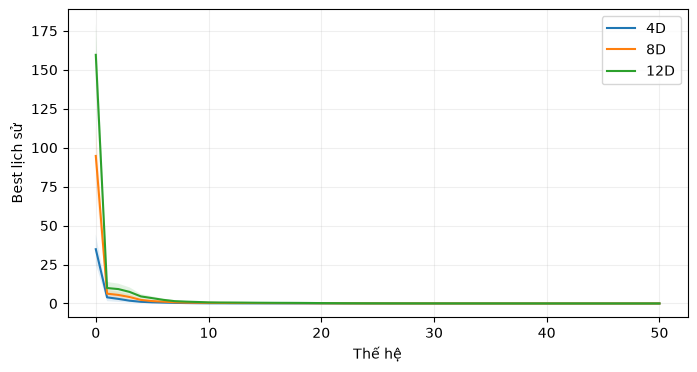

In [5]:
report("rastrigin-multiple-dimensions", compare_configurations(rastrigin, {
    f"{d}D": EHOConfig(dimension=d, population_size=20) for d in (4, 8, 12)
}, seeds));

## 4–5. Dữ liệu máy bơm giả lập và chuyển cấu hình

Mỗi điểm gồm hai lưu lượng, mỗi máy bơm dùng một tọa độ. Chương trình cộng chi phí vận hành với khoản phạt khi tổng lưu lượng thiếu hoặc dư, hoặc khi một bơm vượt giới hạn. Đọc cột lưu lượng và từng khoản chi phí để biết vì sao hai nghiệm có điểm khác nhau.

Ta thử lại cấu hình lấy từ Rastrigin và so với cấu hình 5 cá thể có cùng số lần tính điểm. Mốc Grid Search được tìm bằng cách thử các điểm trên lưới 81 × 81 trong giới hạn. `difference_from_grid` là điểm EHO trừ điểm của mốc lưới. Số dương nghĩa là ở lần chạy đó EHO có điểm cao hơn, tức kém hơn mốc.

,scenario_name,demand,pump_1_max_flow,pump_2_max_flow,pump_1_quadratic_coefficient,pump_1_linear_coefficient,pump_2_quadratic_coefficient,pump_2_linear_coefficient,shortage_penalty,excess_penalty,boundary_penalty
0,Low Demand,35.0,65.0,55.0,0.015,0.7,0.022,0.5,5.0,2.0,100.0
1,Normal Demand,70.0,65.0,55.0,0.015,0.7,0.022,0.5,5.0,2.0,100.0
2,Peak Demand,105.0,65.0,55.0,0.015,0.7,0.022,0.5,5.0,2.0,100.0


Low Demand | Mốc lưới: 32.2971 | Evaluations mỗi lần: 1020


,runs,minimum,mean,median,maximum,std,variance,seconds,evaluations,feasible_rate,violations,mean_difference_from_grid
group,,,,,,,,,,,,
Cơ sở,25,32.244025,37.027517,33.263553,74.496594,9.648623,93.095922,0.022980,1020.0,1.0,0.56,4.730458
Chuyển từ 4D,25,32.240424,32.551141,32.274101,35.115912,0.624230,0.389663,0.016726,1020.0,1.0,0.44,0.254082


,group,seed,flow_1,flow_2,total_flow,shortage,excess,within_capacity,energy,flow_penalty,bounds_penalty,objective,grid_fitness,difference_from_grid
0,Cơ sở,101,18.885922,15.997468,34.883390,0.116610,0.000000,True,32.199268,0.067990,0.0,32.267257,32.297059,-0.029801
1,Cơ sở,102,18.086213,16.999196,35.085409,0.000000,0.085409,True,32.424013,0.014590,0.0,32.438602,32.297059,0.141544
2,Cơ sở,103,18.639356,16.244649,34.884006,0.115994,0.000000,True,32.186808,0.067273,0.0,32.254082,32.297059,-0.042977
3,Cơ sở,104,15.436233,19.503548,34.939780,0.060220,0.000000,True,32.499840,0.018132,0.0,32.517972,32.297059,0.220913
4,Cơ sở,105,17.383105,17.865943,35.249049,0.000000,0.249049,True,32.655953,0.124050,0.0,32.780003,32.297059,0.482945
5,Cơ sở,106,20.290670,14.593077,34.883747,0.116253,0.000000,True,32.360750,0.067574,0.0,32.428324,32.297059,0.131266
6,Cơ sở,107,31.926263,4.209313,36.135576,0.000000,1.135576,True,40.132138,2.579066,0.0,42.711204,32.297059,10.414145
7,Cơ sở,108,16.048500,18.769466,34.817966,0.182034,0.000000,True,32.232441,0.165682,0.0,32.398123,32.297059,0.101064
8,Cơ sở,109,20.372017,15.019007,35.391024,0.000000,0.391024,True,32.957754,0.305799,0.0,33.263553,32.297059,0.966494
9,Cơ sở,110,11.148634,26.971857,38.120491,0.000000,3.120491,True,39.158937,19.474933,0.0,58.633870,32.297059,26.336811


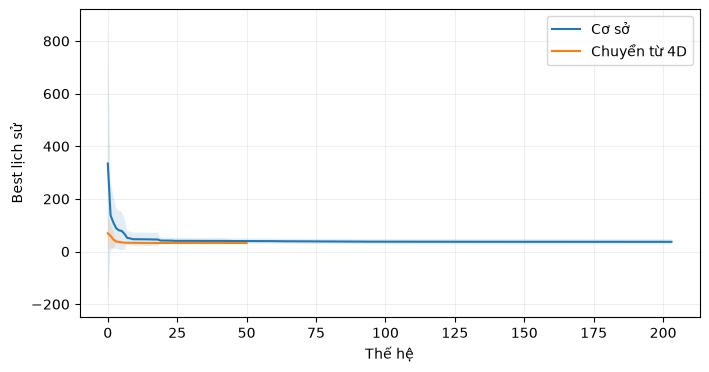

Mean fitness theo cấu hình: {'Cơ sở': 37.02751655346362, 'Chuyển từ 4D': 32.55114054726793}


Normal Demand | Mốc lưới: 86.5969 | Evaluations mỗi lần: 1020


,runs,minimum,mean,median,maximum,std,variance,seconds,evaluations,feasible_rate,violations,mean_difference_from_grid
group,,,,,,,,,,,,
Cơ sở,25,86.583000,87.746707,86.635826,108.856175,4.444319,19.751975,0.023001,1020.0,1.0,0.56,1.149804
Chuyển từ 4D,25,86.582694,86.818870,86.617140,87.837509,0.376215,0.141538,0.017435,1020.0,1.0,0.36,0.221967


,group,seed,flow_1,flow_2,total_flow,shortage,excess,within_capacity,energy,flow_penalty,bounds_penalty,objective,grid_fitness,difference_from_grid
0,Cơ sở,101,42.859722,26.929554,69.789276,0.210724,0.0,True,86.975339,0.222023,0.0,87.197361,86.596902,0.600459
1,Cơ sở,102,39.339493,30.475091,69.814584,0.185416,0.0,True,86.421212,0.171895,0.0,86.593107,86.596902,-0.003795
2,Cơ sở,103,38.964538,30.848946,69.813484,0.186516,0.0,True,86.409643,0.173941,0.0,86.583583,86.596902,-0.013319
3,Cơ sở,104,34.765290,35.037181,69.802471,0.197529,0.0,True,86.990964,0.195088,0.0,87.186052,86.596902,0.589150
4,Cơ sở,105,40.520617,29.285411,69.806028,0.193972,0.0,True,86.503919,0.188126,0.0,86.692046,86.596902,0.095143
5,Cơ sở,106,40.550639,29.263457,69.814096,0.185904,0.0,True,86.522189,0.172801,0.0,86.694990,86.596902,0.098088
6,Cơ sở,107,38.510859,31.301648,69.812507,0.187493,0.0,True,86.410168,0.175769,0.0,86.585937,86.596902,-0.010965
7,Cơ sở,108,38.321247,31.489076,69.810323,0.189677,0.0,True,86.411542,0.179888,0.0,86.591429,86.596902,-0.005473
8,Cơ sở,109,38.777949,31.094462,69.872411,0.127589,0.0,True,86.518778,0.081394,0.0,86.600173,86.596902,0.003270
9,Cơ sở,110,37.297026,32.511687,69.808712,0.191288,0.0,True,86.483998,0.182955,0.0,86.666953,86.596902,0.070051


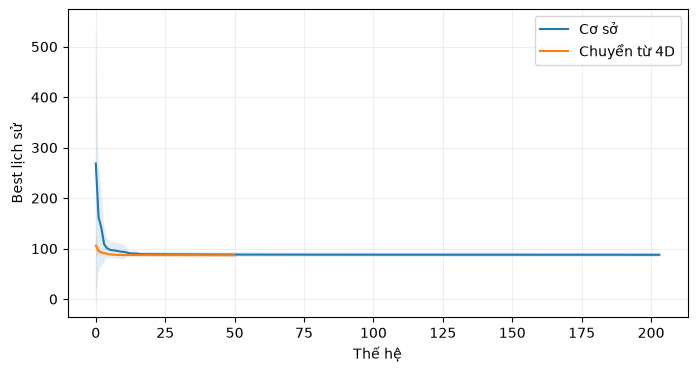

Mean fitness theo cấu hình: {'Cơ sở': 87.74670652836052, 'Chuyển từ 4D': 86.81886980265415}


Peak Demand | Mốc lưới: 162.7597 | Evaluations mỗi lần: 1020


,runs,minimum,mean,median,maximum,std,variance,seconds,evaluations,feasible_rate,violations,mean_difference_from_grid
group,,,,,,,,,,,,
Cơ sở,25,162.778523,983.629636,674.453166,3511.474213,965.432148,932059.231779,0.022902,1020.0,1.0,0.08,820.869921
Chuyển từ 4D,25,162.775790,295.640711,169.887911,1001.107060,222.643095,49569.947532,0.017208,1020.0,1.0,0.24,132.880996


,group,seed,flow_1,flow_2,total_flow,shortage,excess,within_capacity,energy,flow_penalty,bounds_penalty,objective,grid_fitness,difference_from_grid
0,Cơ sở,101,53.968675,50.697901,104.666576,0.333424,0.0,True,163.362389,0.555857,0.0,163.918247,162.759715,1.158532
1,Cơ sở,102,57.938233,31.068029,89.006262,15.993738,0.0,True,127.678254,1278.998219,0.0,1406.676473,162.759715,1243.916758
2,Cơ sở,103,48.758218,30.139565,78.897783,26.102217,0.0,True,104.845647,3406.628566,0.0,3511.474213,162.759715,3348.714499
3,Cơ sở,104,51.649118,41.092688,92.741806,12.258194,0.0,True,133.864596,751.316602,0.0,885.181198,162.759715,722.421483
4,Cơ sở,105,44.541677,52.095119,96.636796,8.363204,0.0,True,146.691980,349.715881,0.0,496.407861,162.759715,333.648146
5,Cơ sở,106,52.325997,34.932003,87.257999,17.742001,0.0,True,122.009734,1573.892949,0.0,1695.902683,162.759715,1533.142968
6,Cơ sở,107,47.080498,54.729562,101.810060,3.189940,0.0,True,159.466878,50.878588,0.0,210.345466,162.759715,47.585751
7,Cơ sở,108,46.754837,47.571855,94.326692,10.673308,0.0,True,139.092327,569.597480,0.0,708.689807,162.759715,545.930092
8,Cơ sở,109,35.271292,54.967492,90.238783,14.761217,0.0,True,137.305963,1089.467568,0.0,1226.773532,162.759715,1064.013817
9,Cơ sở,110,59.962801,28.798614,88.761415,16.238585,0.0,True,128.552255,1318.458138,0.0,1447.010393,162.759715,1284.250678


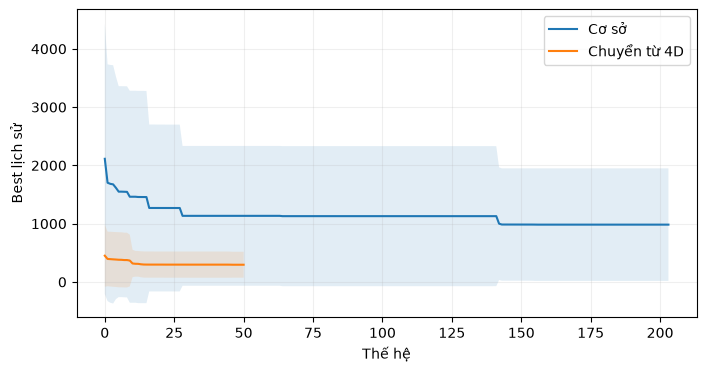

Mean fitness theo cấu hình: {'Cơ sở': 983.6296362031508, 'Chuyển từ 4D': 295.6407110113863}


In [6]:
scenarios = load_pump_scenarios()
display(pd.DataFrame(asdict(scenario) for scenario in scenarios.values()))
selected_config = four_d[selected]
budget = selected_config.population_size * (selected_config.max_generations + 1)
assert budget % book_config.population_size == 0
pump_baseline = replace(book_config, max_generations=budget // book_config.population_size - 1)
for name, scenario in scenarios.items():
    configs = {
        label: replace(config, dimension=2, lower_bounds=0, upper_bounds=scenario.upper_bounds)
        for label, config in (("Cơ sở", pump_baseline), ("Chuyển từ 4D", selected_config))
    }
    groups = compare_configurations(scenario, configs, seeds)
    _, grid_fitness = pump_grid_reference(scenario)
    print(name, "| Mốc lưới:", round(grid_fitness, 4), "| Evaluations mỗi lần:", budget)
    if configs["Cơ sở"] == configs["Chuyển từ 4D"]:
        print("Đối chứng trùng cấu hình chuyển, không thể so sánh ảnh hưởng của cấu hình.")
    details = pd.DataFrame(
        {"group": label, "seed": result.random_seed, **scenario.breakdown(result.best_position)}
        for label, results in groups.items() for result in results
    )
    details["grid_fitness"] = grid_fitness
    details["difference_from_grid"] = details["objective"] - grid_fitness
    frame = results_frame(groups).merge(details, on=["group", "seed"], validate="one_to_one")
    summary = summarize_experiment_results(frame)
    summary["mean_difference_from_grid"] = frame.groupby("group")["difference_from_grid"].mean()
    display(summary, details)
    plot_convergence(groups)
    section = name.lower().replace(" ", "-")
    save_experiment_artifacts("experiment-4", section, MODE, seeds, frame, summary)
    plt.show()
    print("Mean fitness theo cấu hình:", summary["mean"].to_dict())
assert_reproducible(scenario, configs["Cơ sở"], seeds[0])

## 6. Phân tích vượt biên

Trong công thức tách (12.4), số +1 có thể làm tọa độ mới cao hơn giới hạn trên. Điểm ngoài giới hạn cũng có thể ảnh hưởng các bước cập nhật tiếp theo. Thí nghiệm giữ cùng các seed rồi đổi từ khoảng tọa độ chuẩn sang khoảng hẹp để xem số lượt vượt cận thay đổi thế nào. Biểu đồ đếm lượt tọa độ, nên cùng một cá thể có thể được đếm nhiều lần qua nhiều thế hệ.

,group,seed,violating_individuals,violating_coordinates,violating_generations,max_overshoot,best_in_bounds
0,Chuẩn,101,15,17,15,0.914539,True
1,Chuẩn,102,7,7,7,0.817008,True
2,Chuẩn,103,7,7,7,0.813822,True
3,Chuẩn,104,12,12,12,0.898419,True
4,Chuẩn,105,10,10,10,0.907097,True
5,Chuẩn,106,11,11,11,0.935017,True
6,Chuẩn,107,10,13,10,0.815322,True
7,Chuẩn,108,4,5,4,0.717498,True
8,Chuẩn,109,10,11,10,0.949139,True
9,Chuẩn,110,5,5,5,0.912343,True


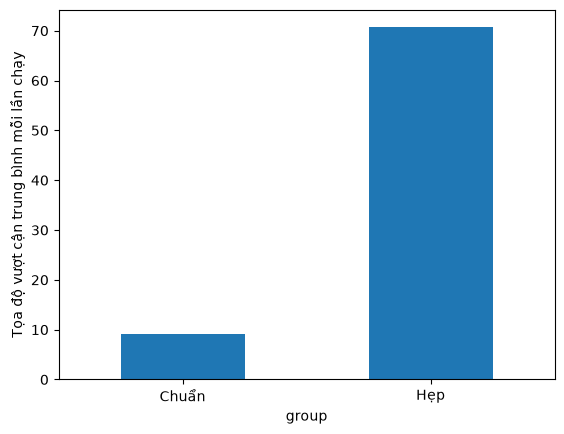

Nhiều lượt vượt cận hơn trong mẫu: Hẹp.


In [7]:
bounds = {"Chuẩn": EHOConfig(dimension=2, population_size=20),
          "Hẹp": EHOConfig(dimension=2, population_size=20, lower_bounds=-0.2, upper_bounds=0.2)}
groups = compare_configurations(rastrigin, bounds, seeds, save_population=True)
frame = results_frame(groups)
frame["max_overshoot"] = [maximum_overshoot(result) for results in groups.values() for result in results]
display(frame[["group", "seed", "violating_individuals", "violating_coordinates",
               "violating_generations", "max_overshoot", "best_in_bounds"]])
totals = frame.groupby("group")["violating_coordinates"].mean()
totals.plot.bar(ylabel="Tọa độ vượt cận trung bình mỗi lần chạy", rot=0)
summary = summarize_experiment_results(frame)
summary["maximum_overshoot"] = frame.groupby("group")["max_overshoot"].max()
save_experiment_artifacts("experiment-4", "boundary", MODE, seeds, frame, summary)
plt.show()
print(f"Nhiều lượt vượt cận hơn trong mẫu: {totals.idxmax()}.")

## Kết luận

Với Rastrigin, ta đọc điểm và số lần tính điểm để xem một cấu hình đã tìm được gì trong thời gian cho phép. Với bài bơm, cần xem thêm nghiệm cho bao nhiêu lưu lượng, có vượt giới hạn không và khoản phạt lớn đến đâu. Kết quả chỉ mô tả các cấu hình, kịch bản và seed trong bảng.